# 🚀 Practice Day 59

**📅 Date:** 2026-11-06  
📁 Category: Phase 2 · Pandas 심화(GroupBy&Pivot) (Round 5/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice groupby aggregation and pivot_table cross-tabulation across two dimensions — store branch and product category
  (groupby 집계와 pivot_table 교차분석을 지점·상품카테고리 두 차원에 걸쳐 연습하기)
- Find which branch and which category drive the most revenue, and where they intersect
  (매출을 가장 많이 견인하는 지점과 카테고리, 그리고 그 둘이 만나는 지점 찾기)

---
# 📂 Dataset

**Dataset Name:** Ashford Mart — Monthly Revenue by Branch & Category / Ashford Mart — 지점별·카테고리별 월간 매출 데이터

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 6 months (Jan-Jun 2024) of monthly revenue for a 6-branch supermarket chain (Midtown, Chelsea, Astoria, SoHo, Forest Hills, Williamsburg), broken down by 5 product categories (Grocery, Produce, Electronics, Household, Apparel). 180 rows total (6 branches × 5 categories × 6 months), revenue is in USD, clean — no missing values or duplicates. The focus is building single-dimension groupby summaries and a branch × category pivot table.
(대형마트 체인 6개 지점(Midtown/Chelsea/Astoria/SoHo/Forest Hills/Williamsburg)에서 6개월(2024년 1~6월) 동안 5개 상품카테고리(Grocery/Produce/Electronics/Household/Apparel)별로 집계된 월간 매출 데이터입니다. 총 180행(6지점×5카테고리×6개월), 매출은 USD 기준이며 결측치·중복 없이 깨끗합니다. groupby로 지점별·카테고리별 집계를, pivot_table로 지점×카테고리 교차표를 만드는 데 초점을 둡니다.)

## Dataset Preview

In [26]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate monthly revenue for a 6-branch supermarket chain, by product category ---
branches = ['Midtown', 'Chelsea', 'Astoria', 'SoHo', 'Forest Hills', 'Williamsburg']
branch_mult = {'Midtown': 1.3, 'Chelsea': 1.15, 'Astoria': 0.9, 'SoHo': 1.4, 'Forest Hills': 0.75, 'Williamsburg': 1.0}

categories = ['Grocery', 'Produce', 'Electronics', 'Household', 'Apparel']
base_revenue = {'Grocery': 42000, 'Produce': 18000, 'Electronics': 26000, 'Household': 15000, 'Apparel': 12000}  # USD per month

months = pd.date_range('2024-01-01', periods=6, freq='MS')

rows = []
for b in branches:
    for cat in categories:
        for i, m in enumerate(months):
            noise = rng.normal(1.0, 0.08)
            revenue = base_revenue[cat] * branch_mult[b] * noise
            revenue = int(round(revenue, -1))  # nearest $10
            rows.append({'month': m, 'branch': b, 'category': cat, 'revenue': revenue})

df = pd.DataFrame(rows).sort_values(['month', 'branch', 'category']).reset_index(drop=True)

df.head(10)


,month,branch,category,revenue
0,2024-01-01,Astoria,Apparel,9770
1,2024-01-01,Astoria,Electronics,21680
2,2024-01-01,Astoria,Grocery,32710
3,2024-01-01,Astoria,Household,14180
4,2024-01-01,Astoria,Produce,15750
5,2024-01-01,Chelsea,Apparel,13280
6,2024-01-01,Chelsea,Electronics,28310
7,2024-01-01,Chelsea,Grocery,56580
8,2024-01-01,Chelsea,Household,18190
9,2024-01-01,Chelsea,Produce,20510


## Dataset Information

In [27]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   month     180 non-null    datetime64[us]
 1   branch    180 non-null    str           
 2   category  180 non-null    str           
 3   revenue   180 non-null    int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 5.8 KB

Shape: (180, 4)


,month,branch,category,revenue
count,180,180,180,180.000000
unique,NaN,6,5,NaN
top,NaN,Astoria,Apparel,NaN
freq,NaN,30,36,NaN
mean,2024-03-16 20:00:00,NaN,NaN,24330.444444
min,2024-01-01 00:00:00,NaN,NaN,8410.000000
25%,2024-02-01 00:00:00,NaN,NaN,14855.000000
50%,2024-03-16 12:00:00,NaN,NaN,19995.000000
75%,2024-05-01 00:00:00,NaN,NaN,31957.500000
max,2024-06-01 00:00:00,NaN,NaN,61930.000000


---
# ❓ Business Questions

1. **(Analysis)** Which branch generated the highest total revenue over the period, and which the lowest?
   (기간 총매출 기준 최고·최저 지점은?)
2. **(Analysis)** Which category generated the highest total revenue overall, and which the lowest?
   (전체 카테고리 중 최고·최저 매출 카테고리는?)
3. **(Analysis)** When you cross-tabulate branch and category, which single combination generated the most revenue — and which the least?
   (지점×카테고리로 교차분석했을 때, 가장 매출이 높은 조합과 가장 낮은 조합은?)
4. **(Visualization)** How do the six branches compare on total revenue?
   (6개 지점의 총매출을 비교하면?)
5. **(Visualization)** How does revenue break down across the branch × category grid all at once?
   (지점×카테고리 조합별 매출은 한눈에 어떻게 보이는가?)

---
# 🔍 Data Cleaning Check


In [28]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
month       0
branch      0
category    0
revenue     0
dtype: int64

Duplicate rows: 0

Dtypes
month       datetime64[us]
branch                 str
category               str
revenue              int64
dtype: object

Column names
['month', 'branch', 'category', 'revenue']

Text columns — unique counts
branch      6
category    5
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which branch generated the highest total revenue over the period, and which the lowest? (기간 총매출 기준 최고·최저 지점은?)

**Result:**  
SoHo earned the most with **$922,720**, and Forest Hills earned the least with **$510,290**.  
(SoHo가 **$922,720**으로 가장 높고, Forest Hills가 **$510,290**으로 가장 낮습니다.)  

**Insight:**  
SoHo earned **$412,430** more than Forest Hills.  
(SoHo는 Forest Hills보다 **$412,430** 더 벌었습니다.)

In [29]:
# Question 1: total revenue by branch
revenue_by_branch = df.groupby('branch')['revenue'].sum().sort_values(ascending=False)

revenue_by_branch

branch
SoHo            922720
Midtown         875900
Chelsea         790750
Williamsburg    672820
Astoria         607000
Forest Hills    510290
Name: revenue, dtype: int64

## Question 2

**Question:** Which category generated the highest total revenue overall, and which the lowest? (최고·최저 매출 카테고리는?)

**Result:**  
Grocery earned the most with **$1,621,910**, and Apparel earned the least with **$471,020**.  
(Grocery가 **$1,621,910**으로 가장 높고, Apparel이 **$471,020**으로 가장 낮습니다.)  

**Insight:**  
Grocery earned **$1,150,890** more than Apparel, and Electronics is second at **$1,015,150**.  
(Grocery는 Apparel보다 **$1,150,890** 더 벌었고, 2위는 Electronics로 **$1,015,150**입니다.)

In [30]:
# Question 2: total revenue by category
revenue_by_category = df.groupby('category')['revenue'].sum().sort_values(ascending=False)

revenue_by_category

category
Grocery        1621910
Electronics    1015150
Produce         689690
Household       581710
Apparel         471020
Name: revenue, dtype: int64

## Question 3

**Question:** When you cross-tabulate branch and category, which single combination generated the most revenue — and which the least? (지점×카테고리 교차분석에서 최고·최저 조합은?)

**Result:**  
The top combination is SoHo and Grocery at **$338,360**, and the lowest is Forest Hills and Apparel at **$53,450**.  
(최고 조합은 SoHo와 Grocery로 **$338,360**이고, 최저 조합은 Forest Hills와 Apparel로 **$53,450**입니다.)  

**Insight:**  
The top combination is **$284,910** above the lowest one.  
(최고 조합은 최저 조합보다 **$284,910** 높습니다.)

In [31]:
# Question 3: branch x category cross-tab
pivot = (
    df.pivot_table(
        index='branch',
        columns='category',
        values='revenue',
        aggfunc='sum',
    )
    .reindex(
        index=revenue_by_branch.index,
        columns=revenue_by_category.index,
    )
)
display(pivot)

stacked = pivot.stack()

display(stacked)

print(stacked.idxmax(), stacked.max())
print(stacked.idxmin(), stacked.min())

category,Grocery,Electronics,Produce,Household,Apparel
branch,,,,,
SoHo,338360,212430,147360,122210,102360
Midtown,317570,203380,141530,118610,94810
Chelsea,298130,181780,124460,103350,83030
Williamsburg,246490,161320,104750,87490,72770
Astoria,227510,140670,93890,80330,64600
Forest Hills,193850,115570,77700,69720,53450


branch        category   
SoHo          Grocery        338360
              Electronics    212430
              Produce        147360
              Household      122210
              Apparel        102360
Midtown       Grocery        317570
              Electronics    203380
              Produce        141530
              Household      118610
              Apparel         94810
Chelsea       Grocery        298130
              Electronics    181780
              Produce        124460
              Household      103350
              Apparel         83030
Williamsburg  Grocery        246490
              Electronics    161320
              Produce        104750
              Household       87490
              Apparel         72770
Astoria       Grocery        227510
              Electronics    140670
              Produce         93890
              Household       80330
              Apparel         64600
Forest Hills  Grocery        193850
              Electronics    115570
  

('SoHo', 'Grocery') 338360
('Forest Hills', 'Apparel') 53450


---
# 📈 Visualization

**Chart 1:** Bar chart — total revenue by branch (막대그래프: 지점별 총매출)

*Interpretation:*  
Revenue falls from SoHo at **$922,720** down to Forest Hills at **$510,290**, with Midtown second at **$875,900**.  
(매출은 SoHo **$922,720**에서 Forest Hills **$510,290**까지 내려가고, Midtown이 **$875,900**으로 두 번째입니다.)  

---

**Chart 2:** Heatmap — revenue by branch × category (히트맵: 지점×카테고리별 매출)

*Interpretation:*  
The darkest cell is SoHo and Grocery at **$338,360**, and the lightest is Forest Hills and Apparel at **$53,450**. In every category column, the branches fall in the same order as the bar chart.  
(가장 진한 칸은 SoHo와 Grocery **$338,360**이고, 가장 옅은 칸은 Forest Hills와 Apparel **$53,450**입니다. 모든 카테고리 열에서 지점 순서는 막대그래프와 같습니다.)


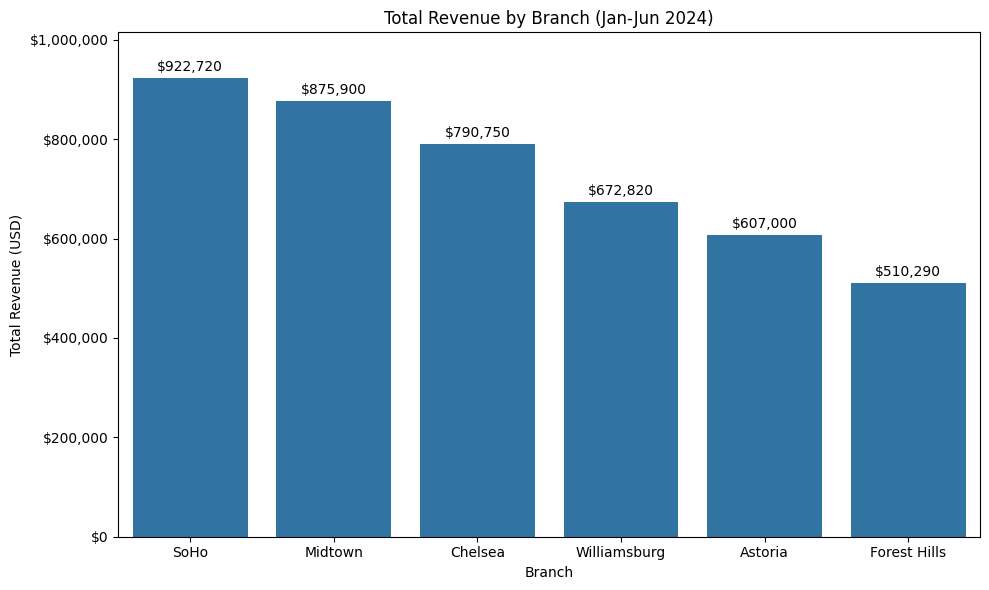

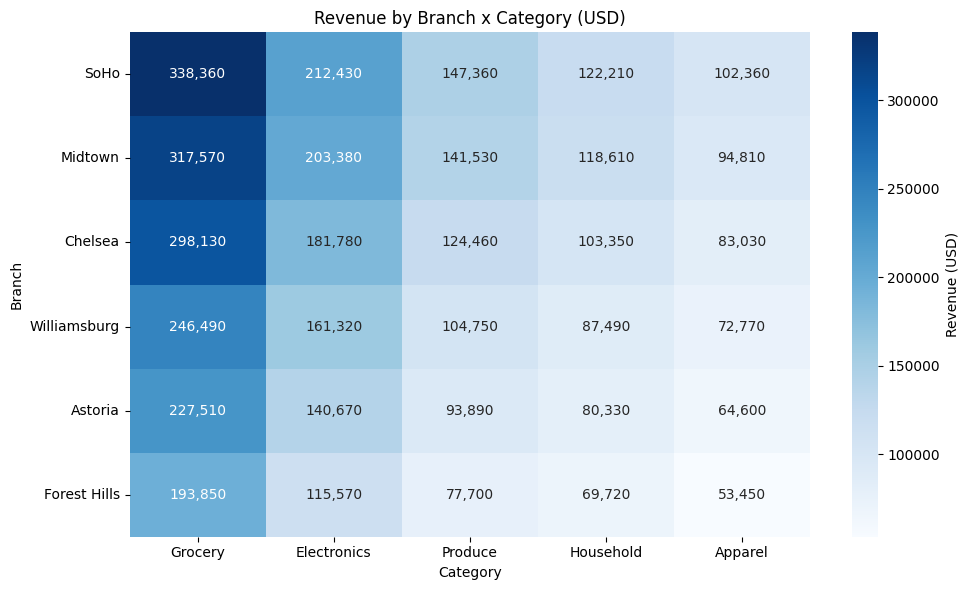

In [32]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: total revenue by branch (bar), same order as the Q1 table
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=revenue_by_branch.index, y=revenue_by_branch.values, ax=ax)
ax.set_title('Total Revenue by Branch (Jan-Jun 2024)')
ax.set_xlabel('Branch')
ax.set_ylabel('Total Revenue (USD)')
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.bar_label(ax.containers[0], fmt='${:,.0f}', padding=3)
ax.margins(y=0.1)
plt.tight_layout()
plt.show()

# Chart 2: branch x category revenue (heatmap), same order as the pivot table
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=',.0f', cmap='Blues', cbar_kws={'label': 'Revenue (USD)'}, ax=ax)
ax.set_title('Revenue by Branch x Category (USD)')
ax.set_xlabel('Category')
ax.set_ylabel('Branch')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- SoHo is the top branch at **$922,720**, and Forest Hills is the lowest at **$510,290**.  
  (SoHo가 **$922,720**으로 1위 지점이고, Forest Hills가 **$510,290**으로 가장 낮습니다.)  
- Grocery is the top category at **$1,621,910**, and Apparel is the lowest at **$471,020**.  
  (Grocery가 **$1,621,910**으로 1위 카테고리이고, Apparel이 **$471,020**으로 가장 낮습니다.)  
- The best cell is SoHo and Grocery at **$338,360**, and the worst is Forest Hills and Apparel at **$53,450**.  
  (최고 칸은 SoHo와 Grocery **$338,360**, 최저 칸은 Forest Hills와 Apparel **$53,450**입니다.)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Treat Grocery in SoHo and Midtown as the revenue core, at **$338,360** and **$317,570**.  
   (SoHo와 Midtown의 Grocery를 매출의 중심으로 봅니다. 각각 **$338,360**, **$317,570**입니다.)  
2. Review Apparel in Forest Hills, the lowest cell at **$53,450**, before planning stock there.  
   (Forest Hills의 Apparel은 가장 낮은 **$53,450**이라, 그곳 재고를 계획하기 전에 살펴봅니다.)  
3. Compare Forest Hills with SoHo first, since the branch gap is **$412,430**.  
   (지점 차이가 **$412,430**이라 Forest Hills와 SoHo를 먼저 비교합니다.)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- I left a duplicate comment line (`product_type`) in the Question 3 cell.  
  (Question 3 셀에 `product_type`이라는 중복 주석 줄이 남아 있었습니다.)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `pivot_table` with `reindex` keeps the branch and category order the same as the Q1 and Q2 tables.  
  (`pivot_table`에 `reindex`를 쓰면 지점과 카테고리 순서가 Q1, Q2 표와 같아집니다.)  
- `stack()` turns the pivot into one series, so `idxmax` and `idxmin` give the top and lowest combination.  
  (`stack()`으로 피벗을 하나의 시리즈로 만들면 `idxmax`와 `idxmin`이 최고·최저 조합을 줍니다.)  


---
# 🧠 Reflection

**What was difficult?**  
Finding the top and lowest cell of the branch by category table.  
(지점×카테고리 표에서 최고·최저 칸을 찾는 것)

**Why?**  
A pivot table has two axes, and `idxmax` on it gives one result per column.  
(피벗 표는 축이 두 개라서 `idxmax`를 쓰면 열마다 결과가 하나씩 나옴)

**How did I solve it?**  
Used `pivot.stack()` to make one series, then `idxmax()` and `idxmin()`.  
(`pivot.stack()`으로 시리즈 하나를 만든 뒤 `idxmax()`와 `idxmin()`을 씀)

**What would I do differently next time?**  
Delete copied comment lines before running the cell.  
(셀을 실행하기 전에 복사해 온 주석 줄을 지우기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
I can build a pivot table and read the top and lowest cell from it.  
(피벗 표를 만들고 거기서 최고·최저 칸을 읽을 수 있습니다.)  

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Day 60: SQL basics  
  (Day 60: SQL 기초)  
